In [2]:
import pandas as pd
import numpy as np
from pathlib import Path

# Load the Excel dataset
df = pd.read_excel("Online Retail.xlsx")

# Preserve the original data for comparison
df_original = df.copy(deep=True)

print("Dataset loaded successfully")
print("Rows and columns:", df.shape)

df.head()

Dataset loaded successfully
Rows and columns: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

print("\nFirst five records:")
display(df.head())

Dataset shape: (541909, 8)

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Data types:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:
missing_report = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})

missing_report = missing_report.sort_values(
    by="Missing_Count",
    ascending=False
)

display(missing_report)

,Missing_Count,Missing_Percentage
CustomerID,135080,24.93
Description,1454,0.27
InvoiceNo,0,0.00
StockCode,0,0.00
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
Country,0,0.00


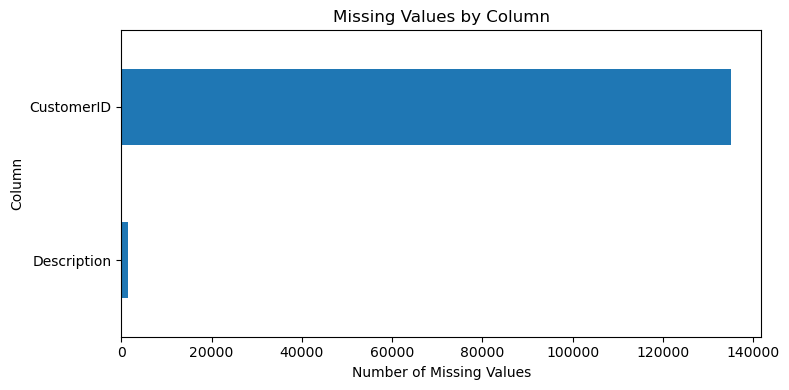

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

missing_counts = df.isnull().sum()
missing_counts = missing_counts[missing_counts > 0]

missing_counts.sort_values().plot(
    kind="barh",
    figsize=(8, 4)
)

plt.title("Missing Values by Column")
plt.xlabel("Number of Missing Values")
plt.ylabel("Column")
plt.tight_layout()
plt.show()

In [6]:
duplicate_count = df.duplicated().sum()

print("Duplicate rows found:", duplicate_count)
print("Duplicate percentage:", round(
    duplicate_count / len(df) * 100, 2
), "%")


Duplicate rows found: 5268
Duplicate percentage: 0.97 %


In [7]:
rows_before = len(df)

df = df.drop_duplicates().copy()

rows_removed = rows_before - len(df)

print("Duplicate rows removed:", rows_removed)
print("Rows remaining:", len(df))

Duplicate rows removed: 5268
Rows remaining: 536641


In [8]:
text_cols = df.select_dtypes(
    include=["object", "string"]
).columns

# Remove extra whitespace around text values
for col in text_cols:
    df[col] = df[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

# Standardise country names
df["Country"] = df["Country"].str.strip().str.title()

# Standardise product descriptions to uppercase
df["Description"] = df["Description"].str.upper()

print("String standardisation completed")

display(df[["Description", "Country"]].head())

String standardisation completed


,Description,Country
0,WHITE HANGING HEART T-LIGHT HOLDER,United Kingdom
1,WHITE METAL LANTERN,United Kingdom
2,CREAM CUPID HEARTS COAT HANGER,United Kingdom
3,KNITTED UNION FLAG HOT WATER BOTTLE,United Kingdom
4,RED WOOLLY HOTTIE WHITE HEART.,United Kingdom


In [9]:
print("Unique countries:", df["Country"].nunique())
print(sorted(df["Country"].dropna().unique()))

Unique countries: 38
['Australia', 'Austria', 'Bahrain', 'Belgium', 'Brazil', 'Canada', 'Channel Islands', 'Cyprus', 'Czech Republic', 'Denmark', 'Eire', 'European Community', 'Finland', 'France', 'Germany', 'Greece', 'Hong Kong', 'Iceland', 'Israel', 'Italy', 'Japan', 'Lebanon', 'Lithuania', 'Malta', 'Netherlands', 'Norway', 'Poland', 'Portugal', 'Rsa', 'Saudi Arabia', 'Singapore', 'Spain', 'Sweden', 'Switzerland', 'United Arab Emirates', 'United Kingdom', 'Unspecified', 'Usa']


In [10]:
# Convert invoice dates into datetime
df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"],
    errors="coerce"
)

# Convert numeric columns safely
df["Quantity"] = pd.to_numeric(
    df["Quantity"],
    errors="coerce"
)

df["UnitPrice"] = pd.to_numeric(
    df["UnitPrice"],
    errors="coerce"
)

df["CustomerID"] = pd.to_numeric(
    df["CustomerID"],
    errors="coerce"
)

print(df.dtypes)

InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object


In [11]:
print("Invalid dates:", df["InvoiceDate"].isna().sum())
print("Missing quantities:", df["Quantity"].isna().sum())
print("Missing prices:", df["UnitPrice"].isna().sum())

print("Zero or negative quantities:",
      (df["Quantity"] <= 0).sum())

print("Negative unit prices:",
      (df["UnitPrice"] < 0).sum())

Invalid dates: 0
Missing quantities: 0
Missing prices: 0
Zero or negative quantities: 10587
Negative unit prices: 2


In [12]:
# Demonstration: create an imputed version of UnitPrice
# Only use this if missing prices are confirmed to be imputable.
unit_price_mean = df["UnitPrice"].mean()

df["UnitPrice_mean_imputed"] = df["UnitPrice"].fillna(
    unit_price_mean
)

print("Mean used:", unit_price_mean)

Mean used: 4.632655674836623


In [13]:
quantity_median = df["Quantity"].median()

df["Quantity_median_imputed"] = df["Quantity"].fillna(
    quantity_median
)

print("Median used:", quantity_median)

Median used: 3.0


In [14]:
if not df["Country"].mode().empty:
    country_mode = df["Country"].mode()[0]

    df["Country_mode_imputed"] = df["Country"].fillna(
        country_mode
    )

    print("Most frequent country:", country_mode)

Most frequent country: United Kingdom


In [15]:
# Demonstration only: sort records by invoice date first
df = df.sort_values("InvoiceDate").copy()

df["Country_ffill_demo"] = df["Country"].ffill()

display(df[["InvoiceDate", "Country",
            "Country_ffill_demo"]].head(10))

,InvoiceDate,Country,Country_ffill_demo
0,2010-12-01 08:26:00,United Kingdom,United Kingdom
1,2010-12-01 08:26:00,United Kingdom,United Kingdom
2,2010-12-01 08:26:00,United Kingdom,United Kingdom
3,2010-12-01 08:26:00,United Kingdom,United Kingdom
4,2010-12-01 08:26:00,United Kingdom,United Kingdom
5,2010-12-01 08:26:00,United Kingdom,United Kingdom
6,2010-12-01 08:26:00,United Kingdom,United Kingdom
7,2010-12-01 08:28:00,United Kingdom,United Kingdom
8,2010-12-01 08:28:00,United Kingdom,United Kingdom
24,2010-12-01 08:34:00,United Kingdom,United Kingdom


In [16]:
demo_cols = [
    "UnitPrice_mean_imputed",
    "Quantity_median_imputed",
    "Country_mode_imputed",
    "Country_ffill_demo"
]

df.drop(
    columns=demo_cols,
    inplace=True,
    errors="ignore"
)

In [17]:
numeric_columns = ["Quantity", "UnitPrice"]

outlier_results = []

for col in numeric_columns:
    values = df[col].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_count = (
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ).sum()

    outlier_results.append({
        "Column": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": int(outlier_count)
    })

outlier_report = pd.DataFrame(outlier_results)

display(outlier_report)

,Column,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Outlier_Count
0,Quantity,1.00,10.00,9.00,-12.50,23.50,58501
1,UnitPrice,1.25,4.13,2.88,-3.07,8.45,39450


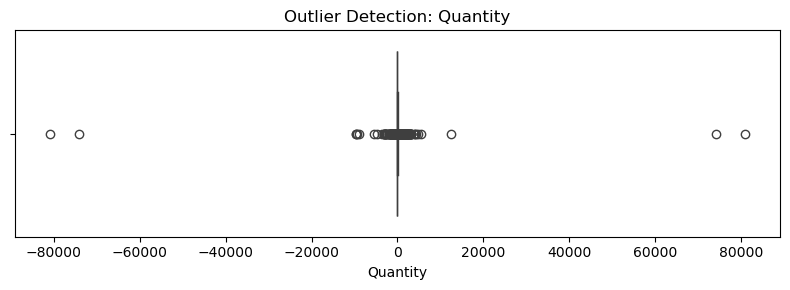

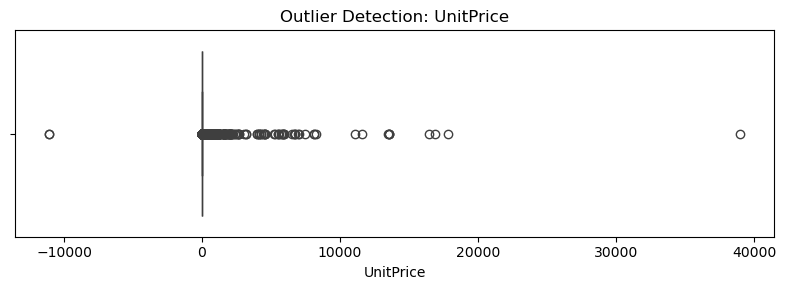

In [18]:
for col in numeric_columns:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df[col])
    plt.title(f"Outlier Detection: {col}")
    plt.tight_layout()
    plt.show()

In [19]:
df_capped = df.copy()

for col in numeric_columns:
    q1 = df_capped[col].quantile(0.25)
    q3 = df_capped[col].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    df_capped[col] = df_capped[col].clip(
        lower=lower_bound,
        upper=upper_bound
    )

print("Original data shape:", df.shape)
print("Capped data shape:", df_capped.shape)

Original data shape: (536641, 8)
Capped data shape: (536641, 8)


In [20]:
quality_log = pd.DataFrame([
    {
        "Issue": "Missing values",
        "Action": "Profiled missing counts and percentages",
        "Reason": "Understand data completeness before treatment"
    },
    {
        "Issue": "Duplicate records",
        "Action": f"Removed {rows_removed} exact duplicate rows",
        "Reason": "Prevent duplicate transaction counting"
    },
    {
        "Issue": "Inconsistent strings",
        "Action": "Trimmed whitespace and standardised selected casing",
        "Reason": "Improve categorical consistency"
    },
    {
        "Issue": "Data types",
        "Action": "Converted date and numeric columns",
        "Reason": "Support reliable analysis"
    },
    {
        "Issue": "Missing-value imputation",
        "Action": "Demonstrated mean, median, mode and forward-fill",
        "Reason": "Compare imputation methods before making final decisions"
    },
    {
        "Issue": "Outliers",
        "Action": "Detected using IQR and created a separate capped copy",
        "Reason": "Evaluate extreme values without losing original records"
    }
])

display(quality_log)

,Issue,Action,Reason
0,Missing values,Profiled missing counts and percentages,Understand data completeness before treatment
1,Duplicate records,Removed 5268 exact duplicate rows,Prevent duplicate transaction counting
2,Inconsistent strings,Trimmed whitespace and standardised selected c...,Improve categorical consistency
3,Data types,Converted date and numeric columns,Support reliable analysis
4,Missing-value imputation,"Demonstrated mean, median, mode and forward-fill",Compare imputation methods before making final...
5,Outliers,Detected using IQR and created a separate capp...,Evaluate extreme values without losing origina...


In [21]:
quality_log.to_csv("data_quality_log.csv", index=False)

In [22]:
print("========== FINAL DATA QUALITY CHECK ==========")

print("Original rows:", len(df_original))
print("Final rows:", len(df))
print("Rows removed:", len(df_original) - len(df))

print("\nRemaining missing values:")
print(df.isnull().sum())

print("\nRemaining duplicate rows:")
print(df.duplicated().sum())

print("\nFinal data types:")
print(df.dtypes)

print("\nFinal dataset shape:", df.shape)

========== FINAL DATA QUALITY CHECK ==========
Original rows: 541909
Final rows: 536641
Rows removed: 5268

Remaining missing values:
InvoiceNo           0
StockCode           0
Description      1455
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135037
Country             0
dtype: int64

Remaining duplicate rows:
0

Final data types:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object

Final dataset shape: (536641, 8)


In [23]:
comparison = pd.DataFrame({
    "Before_Cleaning": df_original.isnull().sum(),
    "After_Cleaning": df.isnull().sum()
})

comparison["Difference"] = (
    comparison["Before_Cleaning"] -
    comparison["After_Cleaning"]
)

display(comparison)

,Before_Cleaning,After_Cleaning,Difference
InvoiceNo,0,0,0
StockCode,0,0,0
Description,1454,1455,-1
Quantity,0,0,0
InvoiceDate,0,0,0
UnitPrice,0,0,0
CustomerID,135080,135037,43
Country,0,0,0


In [24]:
# Save cleaned transaction data
df.to_csv("cleaned_online_retail.csv", index=False)

# Save missing-value comparison
comparison.to_csv("missing_value_comparison.csv")

# Save outlier analysis
outlier_report.to_csv("outlier_report.csv", index=False)

# Save cleaning decisions
quality_log.to_csv("data_quality_log.csv", index=False)

print("All deliverables saved successfully.")

All deliverables saved successfully.
